In [ ]:
import kagglehub

import pandas as pd

# Download latest version
path = kagglehub.dataset_download("saurabh00007/diabetescsv")
print("Path to dataset files:", path)
df=pd.read_csv(path+"/diabetes.csv")
df.head()



Using Colab cache for faster access to the 'diabetescsv' dataset.
Path to dataset files: /kaggle/input/diabetescsv


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df['cluster'] = dbsc_labels
display(df.head())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,cluster
0,6,148,72,35,0,33.6,0.627,50,1,0
1,1,85,66,29,0,26.6,0.351,31,0,0
2,8,183,64,0,0,23.3,0.672,32,1,0
3,1,89,66,23,94,28.1,0.167,21,0,0
4,0,137,40,35,168,43.1,2.288,33,1,0


In [ ]:
print(df['cluster'].unique())

[ 0 -1]


In [ ]:
from sklearn.cluster import AgglomerativeClustering

# Initialize AgglomerativeClustering
# You can tune n_clusters, affinity (e.g., 'euclidean'), and linkage (e.g., 'ward', 'complete', 'average', 'single').
# 'ward' linkage only works with 'euclidean' affinity.
agglomerative = AgglomerativeClustering(n_clusters=3, linkage='ward')

# Fit the model and predict clusters
agg_labels = agglomerative.fit_predict(X_scaled)

print(f"Agglomerative Clustering labels assigned successfully. Unique labels: {np.unique(agg_labels)}")

Agglomerative Clustering labels assigned successfully. Unique labels: [0 1 2]


### Visualizing Agglomerative Clustering Results

Let's visualize the Agglomerative Clusters using the 2D t-SNE components.

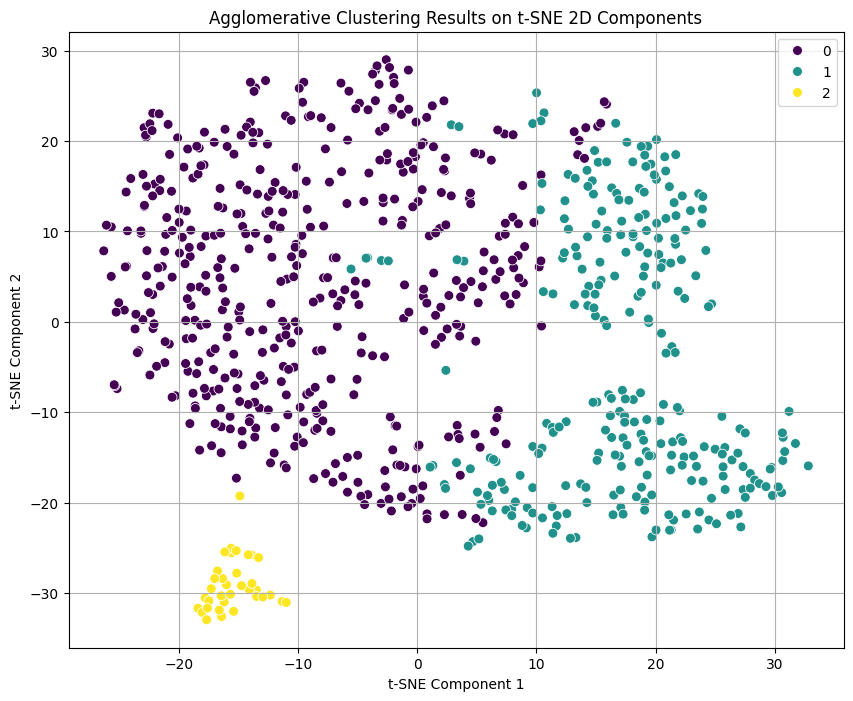

In [ ]:
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=agg_labels, # Color by Agglomerative cluster labels
    palette='viridis',
    legend='full',
    s=50
)
plt.title('Agglomerative Clustering Results on t-SNE 2D Components')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.grid(True)
plt.show()

### Parameter Tuning for Agglomerative Clustering

*   **`n_clusters`**: This is a critical parameter. You can determine the optimal number of clusters by looking at dendrograms. However, generating dendrograms can be computationally intensive for large datasets.
*   **`affinity`**: Measures the similarity of samples. Common choices include 'euclidean', 'l1', 'l2', 'manhattan', 'cosine'. The default for 'ward' linkage is 'euclidean'.
*   **`linkage`**: Determines which distance to use between sets of observation. Options are 'ward', 'complete', 'average', 'single'.
    *   `ward` minimizes the variance of the clusters being merged.
    *   `complete` or `maximum` linkage uses the maximum distances between all observations of the two sets.
    *   `average` linkage uses the average of the distances of each observation of the two sets.
    *   `single` linkage uses the minimum of the distances between all observations of the two sets.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
 9   cluster                   768 non-null    int64  
dtypes: float64(2), int64(8)
memory usage: 60.1 KB


In [ ]:
df.shape

(768, 10)

In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,cluster
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958,-0.002604
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951,0.050998
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000,-1.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000,0.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000,0.000000


In [ ]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0
cluster,0


In [ ]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

In [ ]:
scaler = MinMaxScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

In [ ]:
from sklearn.cluster import KMeans


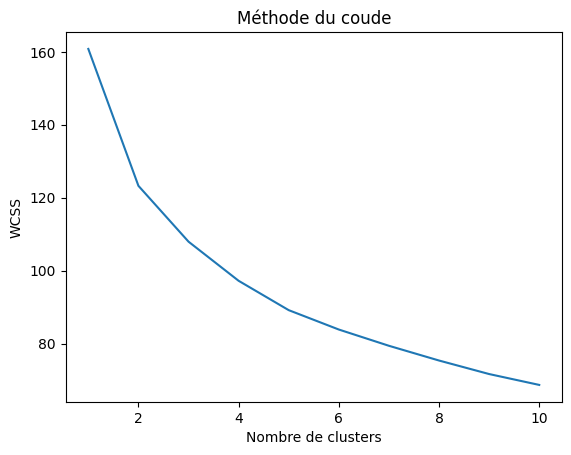

In [ ]:
wcss = []
#wcss est une liste vide pour stocker la somme des carrés intra-cluster
#(Within-Cluster Sum of Squares, WCSS) pour chaque nombre de clusters testé
for i in range(1, 11):
    KM2 = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=0)
    KM2.fit(X_scaled)
    wcss.append(KM2.inertia_)

# Tracez le graphique du coude
plt.plot(range(1, 11), wcss)
plt.title('Méthode du coude' )
plt.xlabel('Nombre de clusters')
plt.ylabel('WCSS') # Within-Cluster Sum of Squares
plt.show()

### Visualizing Hierarchical (Agglomerative) Clustering Results on t-SNE

Let's visualize the clusters obtained from Agglomerative Clustering (which is a form of hierarchical clustering) using the 2D t-SNE components. This will help us understand the spatial distribution of these hierarchical clusters.

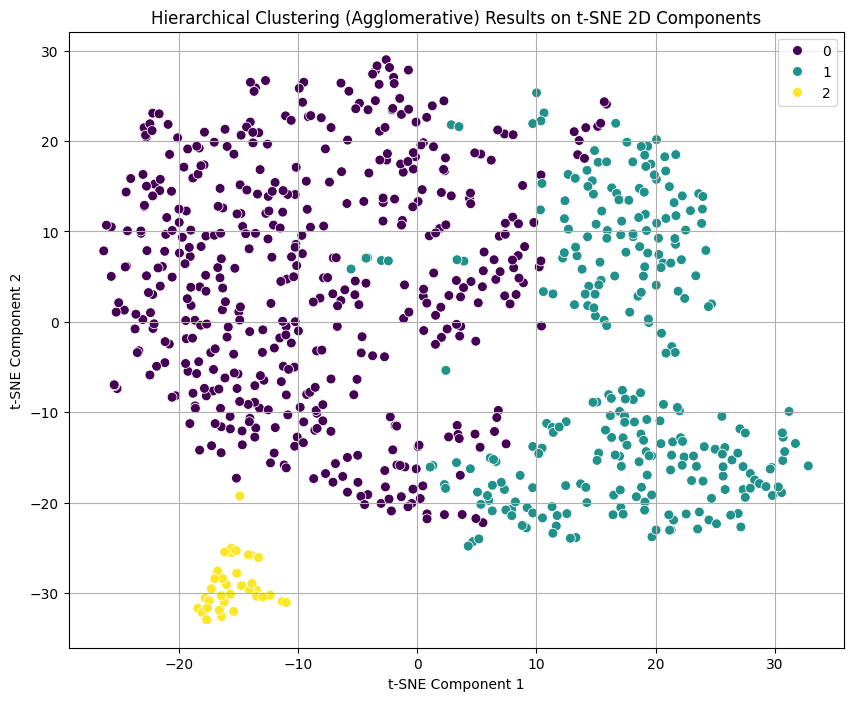

In [ ]:
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=agg_labels, # Color by Agglomerative cluster labels
    palette='viridis',
    legend='full',
    s=50
)
plt.title('Hierarchical Clustering (Agglomerative) Results on t-SNE 2D Components')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import davies_bouldin_score
print("davies_bouldin_score imported successfully.")

davies_bouldin_score imported successfully.


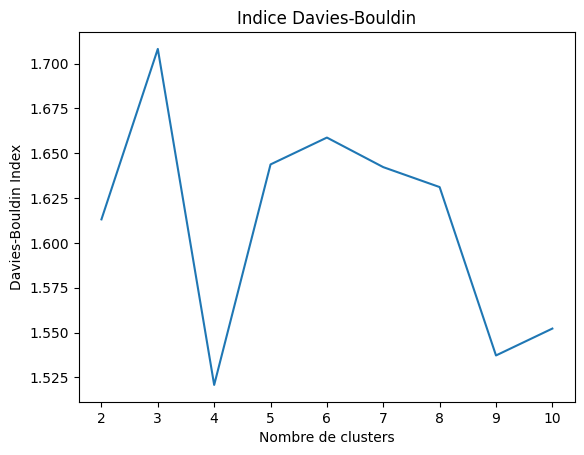

In [ ]:
from sklearn.metrics import davies_bouldin_score

# Calcul de l'indice Davies-Bouldin pour différents nombres de clusters
db_scores = []
for i in range(2, 11):
    KM2 = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=0)
    labels = KM2.fit_predict(X_scaled )
    db_scores.append(davies_bouldin_score(X_scaled , labels))

# Affichage de l'indice Davies-Bouldin pour chaque nombre de clusters
plt.plot(range(2, 11), db_scores)
plt.title('Indice Davies-Bouldin')
plt.xlabel('Nombre de clusters')
plt.ylabel('Davies-Bouldin Index')
plt.show()

In [ ]:
km=KMeans(n_clusters=3,init='k-means++',max_iter=300)
km.fit_predict(X_scaled)
X_scaled['cluster']=km.labels_
cluster_characteristics = X_scaled.groupby('cluster')[['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age']].mean()
display(cluster_characteristics)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
cluster,,,,,,,,
0,0.129237,0.587622,0.540633,0.222692,0.104852,0.473992,0.167963,0.107838
1,0.501760,0.649830,0.629396,0.319002,0.131963,0.508426,0.193720,0.396011
2,0.402395,0.658380,0.624111,0.019308,0.005241,0.457355,0.142764,0.463127


In [ ]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome', 'cluster'],
      dtype='object')

In [ ]:
from sklearn.cluster import DBSCAN

# Initialize DBSCAN. You might need to tune eps and min_samples.
# A common approach for 'eps' is to use a K-distance graph.
# 'min_samples' is often set to 2 * number of dimensions or more.
# For this example, let's start with some arbitrary values.
dbsc = DBSCAN(eps=0.5, min_samples=5)

# Fit the model and predict clusters
dbsc_labels = dbsc.fit_predict(X_scaled)

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(dbsc_labels)) - (1 if -1 in dbsc_labels else 0)
n_noise_ = list(dbsc_labels).count(-1)

print(f"Estimated number of clusters: {n_clusters_}")
print(f"Estimated number of noise points: {n_noise_}")
print("DBSCAN labels assigned successfully.")

Estimated number of clusters: 1
Estimated number of noise points: 2
DBSCAN labels assigned successfully.


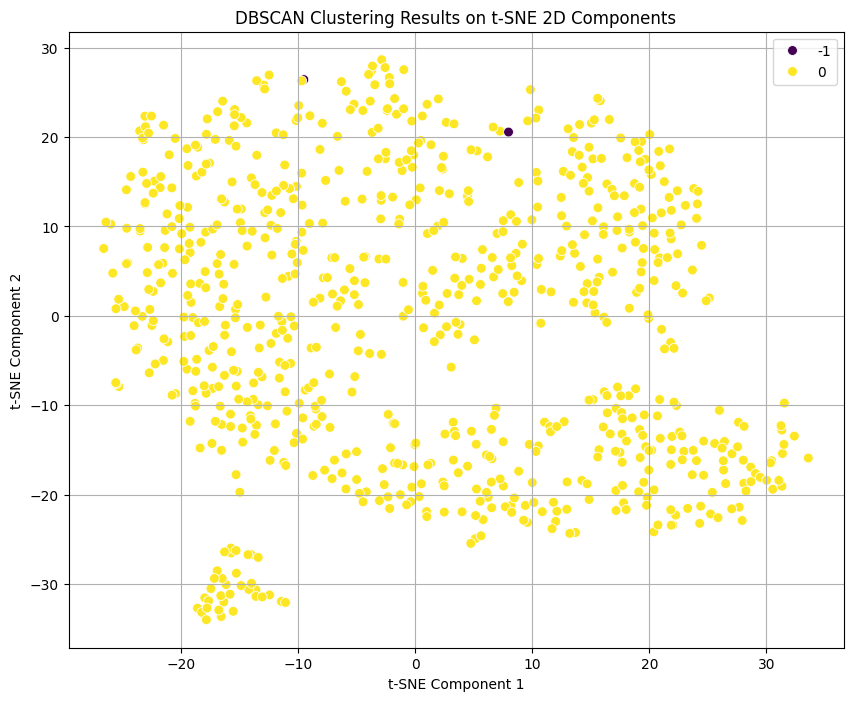

In [ ]:
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=dbsc_labels, # Color by DBSCAN cluster labels
    palette='viridis' if n_clusters_ > 0 else ['gray'], # Use a colormap for clusters, gray for only noise
    legend='full' if n_clusters_ > 0 else False,
    s=50
)
plt.title('DBSCAN Clustering Results on t-SNE 2D Components')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.manifold import TSNE

tsne_3d = TSNE(n_components=3, random_state=42)
X_tsne_3d = tsne_3d.fit_transform(X_scaled)
print("t-SNE 3D dimensionality reduction complete. Shape of X_tsne_3d:", X_tsne_3d.shape)

t-SNE 3D dimensionality reduction complete. Shape of X_tsne_3d: (768, 3)


In [ ]:
from sklearn.metrics import silhouette_score
print("silhouette_score imported successfully.")

silhouette_score imported successfully.


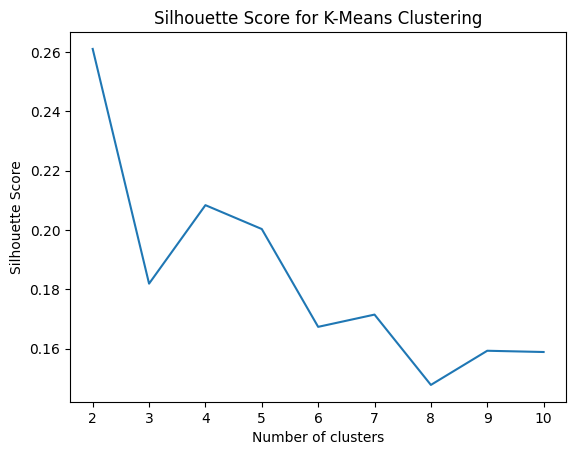

In [ ]:
silhouette_scores = []
for i in range(2, 11):
    KM = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=0)
    labels = KM.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.plot(range(2, 11), silhouette_scores)
plt.title('Silhouette Score for K-Means Clustering')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.show()

In [ ]:
from sklearn.manifold import TSNE
print("TSNE imported successfully.")

TSNE imported successfully.


In [ ]:
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)
print("t-SNE dimensionality reduction complete. Shape of X_tsne:", X_tsne.shape)

t-SNE dimensionality reduction complete. Shape of X_tsne: (768, 2)


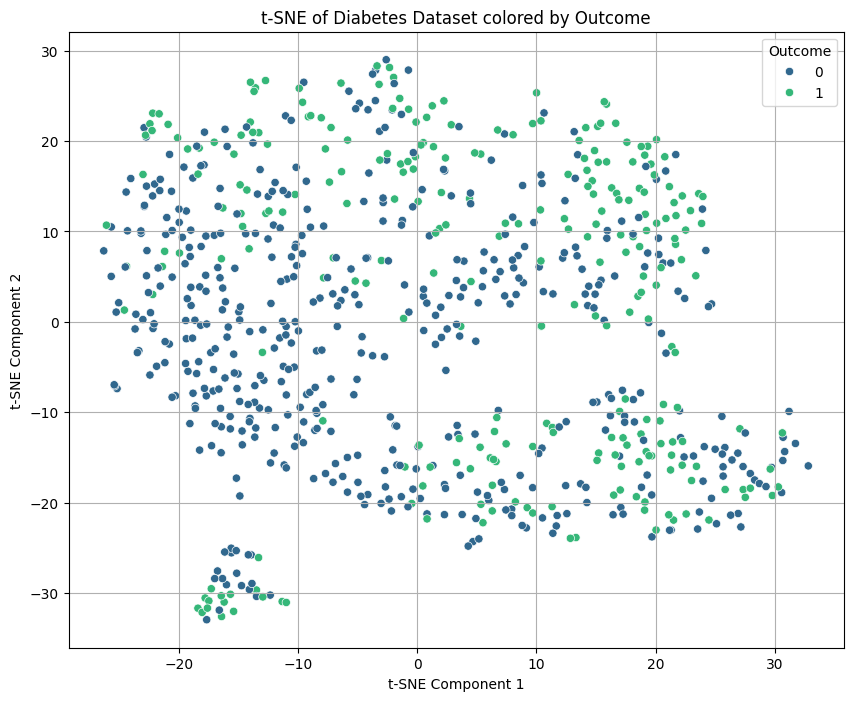

In [ ]:
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=y,
    palette='viridis',
    legend='full'
)
plt.title('t-SNE of Diabetes Dataset colored by Outcome')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.grid(True)
plt.show()


In [ ]:
from mpl_toolkits.mplot3d import Axes3D
print("Axes3D imported successfully.")

Axes3D imported successfully.


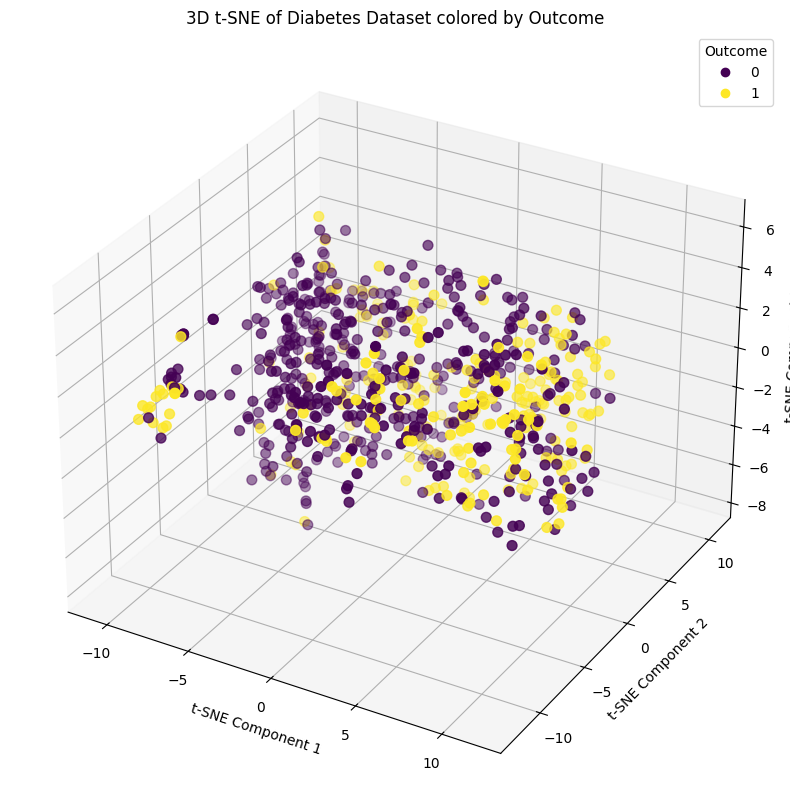

In [ ]:
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_tsne_3d[:, 0],
    X_tsne_3d[:, 1],
    X_tsne_3d[:, 2],
    c=y, # Color points by the 'Outcome' variable
    cmap='viridis', # Choose a colormap
    s=50 # Size of the points
)

ax.set_xlabel('t-SNE Component 1')
ax.set_ylabel('t-SNE Component 2')
ax.set_zlabel('t-SNE Component 3')
ax.set_title('3D t-SNE of Diabetes Dataset colored by Outcome')

# Add a legend
legend = ax.legend(*scatter.legend_elements(), title="Outcome")
for text in legend.get_texts():
    if text.get_text() == '0':
        text.set_text('0 (No Diabetes)')
    elif text.get_text() == '1':
        text.set_text('1 (Diabetes)')

plt.show()

# Task
Calculate the linkage matrix for the `X_scaled` data using the 'ward' linkage method and then plot a dendrogram to visualize the hierarchical clustering structure.

## Calculate Linkage Matrix

### Subtask:
Compute the linkage matrix from the `X_scaled` data using a suitable linkage method (e.g., 'ward' or 'average'). This matrix is essential for constructing the dendrogram.


**Reasoning**:
The subtask requires calculating the linkage matrix. This involves importing the necessary function from `scipy.cluster.hierarchy` and applying it to the `X_scaled` data.



In [ ]:
from scipy.cluster.hierarchy import linkage

# Calculate the linkage matrix using the 'ward' method
linked_data = linkage(X_scaled, method='ward')

print("Linkage matrix computed successfully. Shape of linked_data:", linked_data.shape)

Linkage matrix computed successfully. Shape of linked_data: (767, 4)


## Plot Dendrogram

### Subtask:
Generate and display a dendrogram based on the calculated linkage matrix. The dendrogram will illustrate the hierarchical clustering process, showing how data points are grouped into clusters at various levels.


**Reasoning**:
To visualize the hierarchical clustering structure, I need to generate a dendrogram using the `linked_data` matrix. This involves importing `dendrogram` and then plotting it with appropriate labels and title.



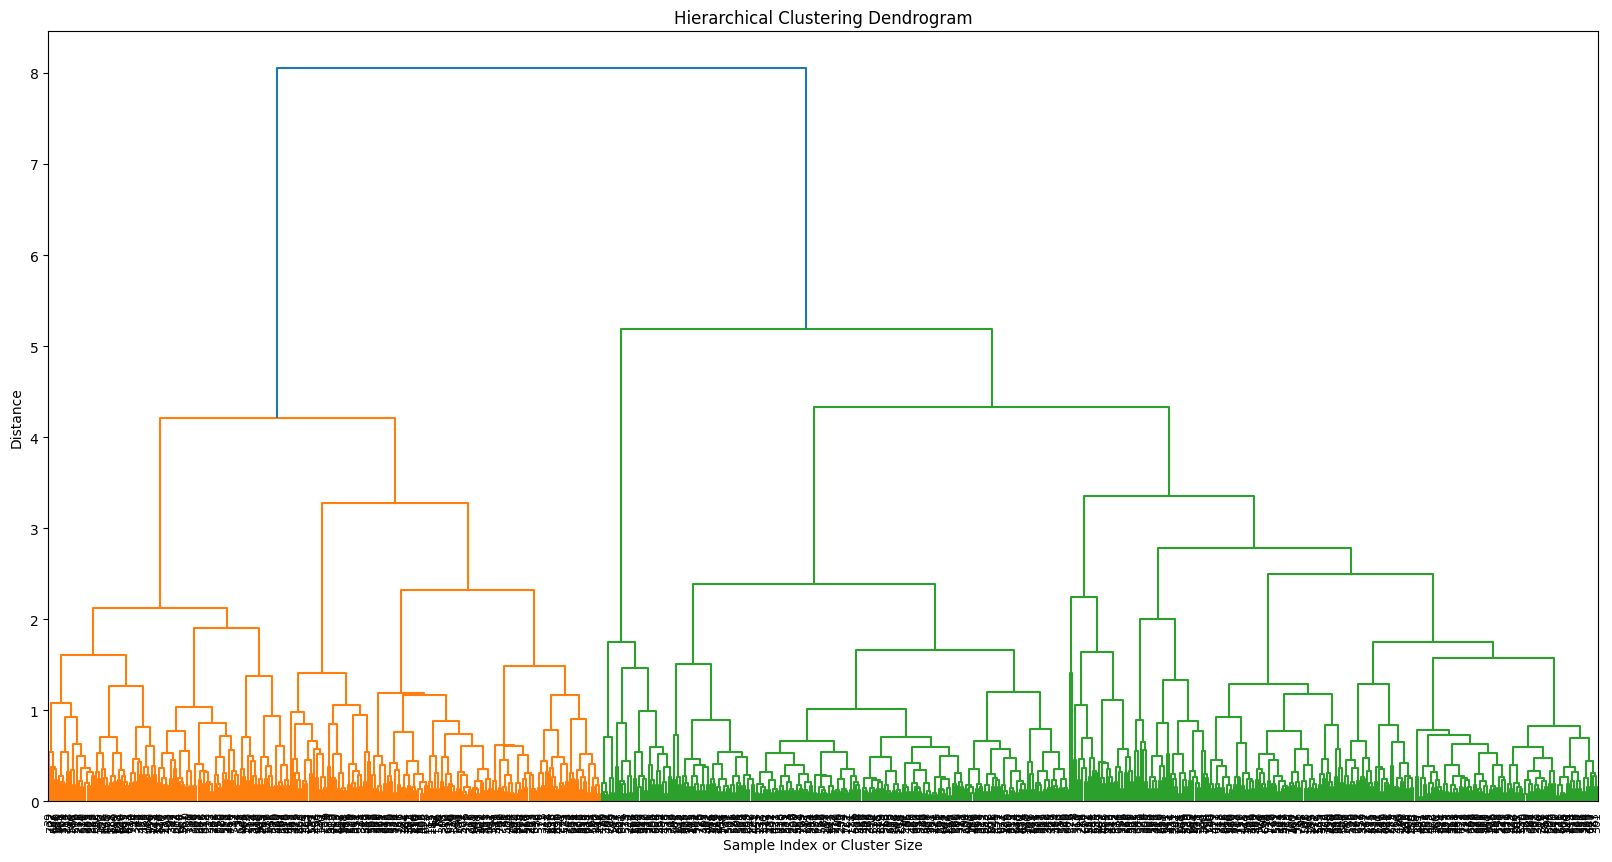

In [ ]:
from scipy.cluster.hierarchy import dendrogram

plt.figure(figsize=(20, 10))
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Sample Index or Cluster Size')
plt.ylabel('Distance')
dendrogram(
    linked_data,
    leaf_rotation=90.,  # rotates the x axis labels
    leaf_font_size=8.,  # font size for the x axis labels
)
plt.show()

,Pregnancies,Glucose,BloodPressure,BMI,Age,Outcome
cluster,,,,,,
-1,3.000000,197.000000,70.000000,35.700000,46.500000,0.500000
0,3.847258,120.695822,69.103133,31.982898,33.206266,0.348564
